# 07 · Análisis del monitoreo

**Pregunta:** ¿qué detectó el monitoreo en los 10 lotes y qué se hizo con eso?

Fuentes (exportadas con `src/exportar_evidencia.py`): `docs/monitoreo.csv`, `docs/alertas.csv`, `docs/reentrenamientos.csv`, y `data/simulacion/por_lote.csv` (`src/analisis_final.py`).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SIM = RAIZ / "data" / "simulacion"
DOCS = RAIZ / "docs"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [2]:
mon = pd.read_csv(DOCS / "monitoreo.csv")
alertas = pd.read_csv(DOCS / "alertas.csv")
print(f"{len(mon)} métricas, {len(alertas)} alertas en {mon['lote_simulacion'].nunique()} lotes")
alertas.groupby(["tipo", "metrica"]).size().rename("alertas").to_frame()

536 métricas, 16 alertas en 10 lotes


alertas
tipo      metrica                      
datos     pct_fuera_rango             1
          pct_nulos                   2
          psi                         1
desempeno roc_auc_lote                2
modelo    psi_probabilidad            3
negocio   clarificantes_semana        5
sistema   latencia_p95_ms             2

## 1. Alertas por lote (con severidad, quién la recibe y acción)

In [3]:
cols = ["lote_simulacion", "tipo", "metrica", "variable", "valor", "umbral", "severidad", "quien_la_recibe", "accion"]
alertas[[c for c in cols if c in alertas.columns]].sort_values(["lote_simulacion", "tipo"])

,lote_simulacion,tipo,metrica,variable,valor,umbral,severidad,quien_la_recibe,accion
0,1,modelo,psi_probabilidad,probabilidad,5.563540,0.250,Media,Analista de datos,Revisar junto con la deriva de las features
1,1,sistema,latencia_p95_ms,NaN,1464.662500,500.000,Baja,Soporte de la API,Revisar arranque en frío y recursos
2,2,modelo,psi_probabilidad,probabilidad,5.216115,0.250,Media,Analista de datos,Revisar junto con la deriva de las features
3,2,negocio,clarificantes_semana,NaN,5.000000,2.000,Media,Jefe de producción,Aplicar solo a los 2 lotes de mayor probabilidad
4,3,negocio,clarificantes_semana,NaN,5.000000,2.000,Media,Jefe de producción,Aplicar solo a los 2 lotes de mayor probabilidad
5,5,negocio,clarificantes_semana,NaN,3.000000,2.000,Media,Jefe de producción,Aplicar solo a los 2 lotes de mayor probabilidad
6,6,negocio,clarificantes_semana,NaN,3.000000,2.000,Media,Jefe de producción,Aplicar solo a los 2 lotes de mayor probabilidad
7,7,negocio,clarificantes_semana,NaN,4.000000,2.000,Media,Jefe de producción,Aplicar solo a los 2 lotes de mayor probabilidad
8,8,datos,pct_nulos,generacion_levadura,0.500000,0.200,Media,Responsable de la bitácora,Completar el registro en planta
9,8,datos,pct_nulos,levadura_nueva,0.500000,0.200,Media,Responsable de la bitácora,Completar el registro en planta


## 2. Deriva de datos: PSI por variable

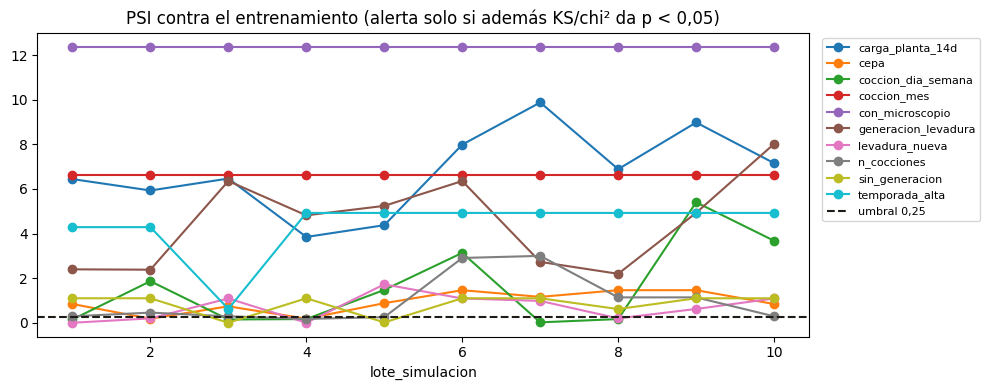

variable,carga_planta_14d,cepa,coccion_dia_semana,coccion_mes,con_microscopio,generacion_levadura,levadura_nueva,n_cocciones,sin_generacion,temporada_alta
lote_simulacion,,,,,,,,,,
1,6.44,0.84,0.15,6.62,12.38,2.40,0.00,0.29,1.10,4.29
2,5.93,0.19,1.87,6.62,12.38,2.38,0.20,0.46,1.10,4.29
3,6.47,0.74,0.15,6.62,12.38,6.36,1.09,0.29,0.00,0.62
4,3.85,0.19,0.17,6.62,12.38,4.82,0.00,0.18,1.10,4.93
5,4.38,0.88,1.47,6.62,12.38,5.24,1.73,0.26,0.02,4.93
6,7.99,1.46,3.14,6.62,12.38,6.36,1.09,2.91,1.10,4.93
7,9.88,1.16,0.02,6.62,12.38,2.73,0.98,3.00,1.10,4.93
8,6.89,1.46,0.17,6.62,12.38,2.20,0.20,1.14,0.62,4.93
9,8.98,1.46,5.40,6.62,12.38,4.93,0.62,1.14,1.10,4.93


In [4]:
psi = (mon[(mon["tipo"] == "datos") & (mon["metrica"] == "psi")]
         .pivot_table(index="lote_simulacion", columns="variable", values="valor"))
fig, eje = plt.subplots(figsize=(10, 4))
psi.plot(ax=eje, marker="o")
eje.axhline(0.25, color="#1E1A16", linestyle="--", label="umbral 0,25")
eje.set_title("PSI contra el entrenamiento (alerta solo si además KS/chi² da p < 0,05)")
eje.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()
psi.round(2)

In [5]:
# ¿Qué variables usa de verdad el modelo en producción (champion v1)?
# Se lee la copia exportada del champion (tests/fixtures/modelo), así esta celda corre sin MLflow.
# Una variable "tiene peso" si alguno de sus coeficientes (incluida su columna de faltantes
# o sus categorías) es distinto de 0. Solo la deriva de esas variables puede cambiar una predicción.
import json
import sys

import mlflow.sklearn

sys.path.insert(0, str(RAIZ))
from src.pipeline import FEATURES
from src.monitoreo import CALENDARIO, CON_PESO_EN_MODELO

modelo_v1 = mlflow.sklearn.load_model(str(RAIZ / "tests" / "fixtures" / "modelo"))
info_v1 = json.loads((RAIZ / "tests" / "fixtures" / "info_modelo.json").read_text())
logistica = modelo_v1.named_steps["modelo"]
columnas = modelo_v1.named_steps["prep"].get_feature_names_out()


def variable_original(columna):
    """'num__missingindicator_generacion_levadura' -> 'generacion_levadura'; 'cat__cepa_K-97' -> 'cepa'."""
    coincidencias = [f for f in FEATURES if f in columna]
    return max(coincidencias, key=len)   # la coincidencia más larga evita confundir variables parecidas


coef = pd.DataFrame({"columna": columnas, "coeficiente": logistica.coef_[0]})
coef["variable"] = coef["columna"].map(variable_original)

pesos = (coef.assign(abs_coef=coef["coeficiente"].abs())
             .groupby("variable")["abs_coef"].max()
             .rename("mayor |coeficiente|")
             .to_frame())
pesos["tiene peso"] = pesos["mayor |coeficiente|"] > 1e-8
pesos["PSI alerta en monitoreo"] = pesos.index.isin(CON_PESO_EN_MODELO)
pesos["de calendario"] = pesos.index.isin(CALENDARIO)
pesos = pesos.sort_values("mayor |coeficiente|", ascending=False)

print(f"Champion versión {info_v1['version']} (run {info_v1['run_id']}): "
      f"{type(logistica).__name__}, penalty={logistica.get_params().get('penalty')}, C={logistica.get_params().get('C')}")
print(f"{int(pesos['tiene peso'].sum())} de {len(pesos)} variables tienen peso en el modelo")

# Comprobación: la lista CON_PESO_EN_MODELO de src/monitoreo.py debe coincidir con los coeficientes
con_peso = set(pesos.index[pesos["tiene peso"]])
if con_peso != set(CON_PESO_EN_MODELO):
    print(f"ATENCIÓN: los coeficientes dicen {sorted(con_peso)}, "
          f"pero src/monitoreo.py usa {sorted(CON_PESO_EN_MODELO)}")
else:
    print("La regla de alertas usa exactamente las variables con peso en el modelo.")
pesos.round(4)

Champion versión 1 (run e96be0e9960b47bf836869be8483a3c8): LogisticRegression, penalty=l1, C=0.14445251022763064
2 de 10 variables tienen peso en el modelo
La regla de alertas usa exactamente las variables con peso en el modelo.


,mayor |coeficiente|,tiene peso,PSI alerta en monitoreo,de calendario
variable,,,,
generacion_levadura,0.1588,True,True,False
temporada_alta,0.0915,True,True,True
carga_planta_14d,0.0000,False,False,False
cepa,0.0000,False,False,False
coccion_dia_semana,0.0000,False,False,False
coccion_mes,0.0000,False,False,True
con_microscopio,0.0000,False,False,False
levadura_nueva,0.0000,False,False,False
n_cocciones,0.0000,False,False,False


**Qué variables pueden alertar por deriva.** La tabla de arriba muestra que el champion (regresión logística con penalización L1) dejó solo **2 de 10 variables con peso**: `generacion_levadura` (|coef.| 0,159) y `temporada_alta` (0,092). Las otras 8 tienen coeficiente 0: si su distribución cambia, ninguna predicción cambia. Por eso el PSI alerta solo en esas dos (y `temporada_alta` no alerta porque es de calendario: en producción siempre llegan meses posteriores al entrenamiento). La deriva de las demás se mide y se guarda en `MONITOREO`, pero no genera alerta.

Esto explica dos cambios grandes que **no** alertan:

- `con_microscopio`: en el entrenamiento, 171 de 176 lotes no tenían microscopio; en la simulación, los 51 sí (se compró en agosto). Es un cambio real del proceso, pero el modelo no usa esa variable.
- `carga_planta_14d`: su PSI es alto en varios lotes normales, pero tampoco tiene peso en el modelo.

La calidad de los datos (nulos, valores fuera de rango, cepas nuevas) sí alerta en todas las variables, porque un dato faltante o imposible es un problema aunque el modelo no use la variable.

**La deriva inducida del lote 10 se detecta.** Dos alertas aparecen **solo** en ese lote y en ningún lote normal:

| Alerta | Lote 10 | Lotes 1 a 9 |
|---|---|---|
| PSI de `generacion_levadura` | 8,02 (KS p = 0,0001) | sin alerta |
| `carga_planta_14d` fuera del rango del entrenamiento [0, 15] | 100 % de los lotes | 0 % |

Lo que se alteró en ese lote (planta saturada: +12 lotes en 14 días; levadura reutilizada hasta la 4.ª y 5.ª generación) es exactamente lo que detectan estas dos alertas.

### Alertas en lotes sin alterar y cómo ajustaría cada umbral

Con la regla final hay 16 alertas. Las de deriva de entradas aparecen solo en el lote 10, pero otras cuatro alertas aparecen también en lotes que no se alteraron. Ninguna dispara un reentrenamiento (solo lo hace la caída del ROC-AUC), pero cada una se revisa:

**1. PSI de la probabilidad en los lotes 1 y 2 (5,56 y 5,22).** Es una falsa alarma de deriva. Causa: esos dos lotes son de agosto y el 100 % de sus cocciones es de temporada alta, contra el 53 % del entrenamiento. Como `temporada_alta` es una de las dos variables del modelo, las probabilidades suben (0,613 a 0,672). Es el efecto estacional que el modelo debe capturar, no un cambio en los datos; desde septiembre (lote 3) la alerta desaparece. El tamaño del PSI también está inflado: con solo 2 variables, el modelo produce pocas probabilidades distintas (14 en el entrenamiento, 10 en producción), y con 6 predicciones por semana casi todos los tramos del PSI quedan vacíos.
*Ajuste:* calcular el PSI de la probabilidad sobre una ventana de al menos 30 predicciones (4 a 5 semanas) y compararlo contra el entrenamiento de la misma temporada. En el lote 10 la alerta (8,70) sí es real: la generación 4–5 baja todas las probabilidades a 0,494–0,527, por debajo de cualquier lote normal.

**2. Clarificantes por encima del presupuesto en los lotes 2, 3, 5, 6 y 7 (3 a 5 por semana, presupuesto 2).** No es deriva: es una alerta de negocio que funciona como se diseñó. El umbral fijo (0,6216) se calculó en el entrenamiento para recomendar ~2 lotes por semana, pero en producción muchos lotes quedan en 0,622, apenas 0,0004 por encima, y todos los lotes con la misma generación y temporada empatan en la misma probabilidad.
*Ajuste:* la acción ya está definida: el jefe de producción aplica el clarificante solo a los 2 lotes con mayor probabilidad (política top-2). La recomendación es que la API pase de umbral fijo a top-2 por semana.

**3. Latencia p95 en los lotes 1 y 9 (1,46 s y 1,08 s, umbral 500 ms).** En ambos casos es la primera predicción después de que la API arrancó o pasó un rato sin recibir solicitudes (1,84 s en el lote 1; 1,12 s en el lote 9, que se reenvió una hora después para probar la lectura desde Snowflake). La siguiente predicción ya baja a 0,06–0,33 s, y en los demás lotes el p95 queda entre 27 y 88 ms.
En la primera simulación también alertaban los lotes 8 y 10 (8,0 s y 4,6 s): la API consultaba el alias en MLflow dentro de la solicitud. Al mover esa consulta a un hilo de fondo, esas dos alertas desaparecieron, lo que confirma la causa.
*Ajuste:* hacer una predicción de calentamiento al arrancar la API, o medir el p95 sobre al menos 20 solicitudes, para que una sola solicitud lenta no dispare la alerta.

**4. Nulos en `generacion_levadura` y `levadura_nueva` en el lote 8 (50 %, umbral 20 %).** No es falsa alarma: 3 de 6 cocciones se registraron sin generación de levadura (en el entrenamiento era el 15 %). `levadura_nueva` se deriva de la generación, por eso falla junto con ella. El modelo lo tolera (imputa la mediana y usa un indicador de faltante), pero es una falla de registro en planta.
*Acción:* avisar al jefe de producción para que se registre la generación al momento de la cocción.

## 3. Desempeño por lote contra la CV del PSet 3 (deriva conceptual)

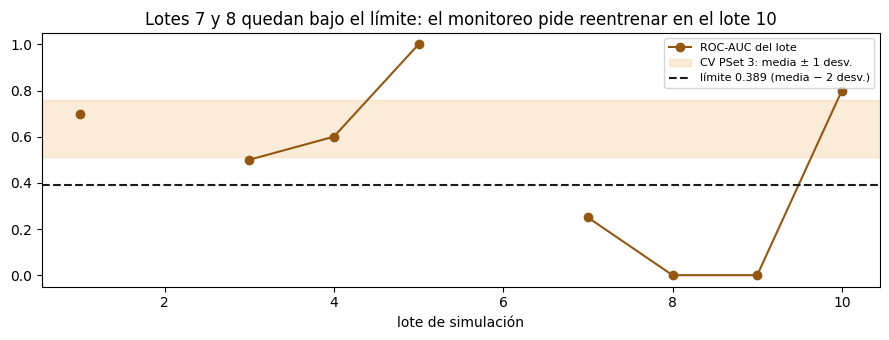

,lote,lotes,merma_alta,roc_auc
0,1,6,5,0.70
1,2,6,6,NaN
2,3,6,5,0.50
3,4,6,5,0.60
4,5,5,3,1.00
5,6,3,3,NaN
6,7,5,4,0.25
7,8,6,4,0.00
8,9,2,1,0.00
9,10,6,5,0.80


In [6]:
CV_MEDIA, CV_STD = 0.635, 0.123
LIMITE = CV_MEDIA - 2 * CV_STD
lote = pd.read_csv(SIM / "por_lote.csv")
fig, eje = plt.subplots(figsize=(9, 3.5))
eje.plot(lote["lote"], lote["roc_auc"], marker="o", color="#94570F", label="ROC-AUC del lote")
eje.axhspan(CV_MEDIA - CV_STD, CV_MEDIA + CV_STD, color="#E8A33D", alpha=0.2, label="CV PSet 3: media ± 1 desv.")
eje.axhline(LIMITE, color="#1E1A16", linestyle="--", label=f"límite {LIMITE:.3f} (media − 2 desv.)")
eje.set_xlabel("lote de simulación")
eje.set_ylim(-0.05, 1.05)
eje.set_title("Lotes 7 y 8 quedan bajo el límite: el monitoreo pide reentrenar en el lote 10")
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()
lote[["lote", "lotes", "merma_alta", "roc_auc"]]

## 4. Negocio: costo de los errores por lote

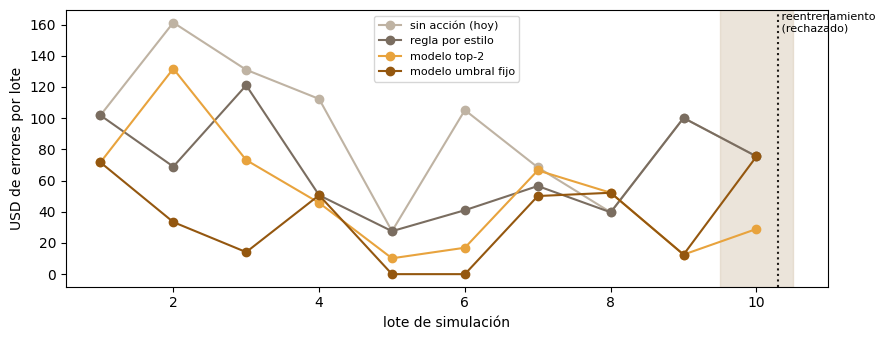

In [7]:
fig, eje = plt.subplots(figsize=(9, 3.5))
for col, nombre, color in [("usd_lote_sin_accion", "sin acción (hoy)", "#BFB3A3"),
                           ("usd_lote_regla_estilo", "regla por estilo", "#7A6D60"),
                           ("usd_lote_modelo_top2", "modelo top-2", "#E8A33D"),
                           ("usd_lote_modelo_umbral", "modelo umbral fijo", "#94570F")]:
    eje.plot(lote["lote"], lote[col], marker="o", label=nombre, color=color)
eje.axvspan(9.5, 10.5, color="#D9CBB6", alpha=0.5)
eje.axvline(10.3, color="#1E1A16", linestyle=":")
eje.text(10.3, eje.get_ylim()[1] * 0.92, " reentrenamiento\n (rechazado)", fontsize=8)
eje.set_xlabel("lote de simulación")
eje.set_ylabel("USD de errores por lote")
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Reentrenamientos

In [8]:
re = pd.read_csv(DOCS / "reentrenamientos.csv")
cols = [c for c in ["start_time", "tags.mlflow.runName", "tags.motivo_disparo", "tags.recomendacion",
                    "metrics.champion_costo_por_lote", "metrics.challenger_costo_por_lote",
                    "metrics.champion_roc_auc", "metrics.challenger_roc_auc", "params.inicio_ventana_evaluacion"]
        if c in re.columns]
re[cols].sort_values("start_time")

,start_time,tags.mlflow.runName,tags.motivo_disparo,tags.recomendacion,metrics.champion_costo_por_lote,metrics.challenger_costo_por_lote,metrics.champion_roc_auc,metrics.challenger_roc_auc,params.inicio_ventana_evaluacion
9,2026-11-26 01:48:16.767000+00:00,reentrenamiento 2026-11-26 01:48,NaN,MANTENER,33.042265,50.661735,0.457143,0.457143,2026-09-07
8,2026-11-26 01:54:36.910000+00:00,reentrenamiento 2026-11-26 01:54,NaN,PROMOVER,50.661735,50.661735,0.457143,0.457143,2026-09-07
7,2026-11-26 02:36:35.535000+00:00,reentrenamiento 2026-11-26 02:36,manual,MANTENER,33.042265,50.661735,0.457143,0.457143,2026-09-07
6,2026-11-26 20:34:32.654000+00:00,reentrenamiento 2026-11-26 20:34,calendario,MANTENER,33.042265,50.661735,0.457143,0.457143,2026-09-07
5,2026-11-26 20:55:10.012000+00:00,reentrenamiento 2026-11-26 20:55,desempeño: ROC-AUC bajo 0.389 (media CV − 2 de...,MANTENER,33.042265,50.661735,0.457143,0.457143,2026-09-07
4,2026-11-27 18:59:50.313000+00:00,reentrenamiento 2026-11-27 18:59,desempeño: ROC-AUC bajo 0.389 (media CV − 2 de...,MANTENER,33.042265,50.661735,0.457143,0.457143,2026-09-07
3,2026-11-27 20:14:55.679000+00:00,reentrenamiento 2026-11-27 20:14,desempeño: ROC-AUC bajo 0.389 (media CV − 2 de...,MANTENER,33.042265,50.661735,0.457143,0.457143,2026-09-07
2,2026-11-27 21:11:03.397000+00:00,reentrenamiento 2026-11-27 21:11,desempeño: ROC-AUC bajo 0.389 (media CV − 2 de...,MANTENER,33.042265,50.661735,0.457143,0.457143,2026-09-07
1,2026-11-28 00:43:24.778000+00:00,reentrenamiento 2026-11-28 00:43,calendario,MANTENER,33.042265,50.661735,0.457143,0.457143,2026-09-07
0,2026-11-28 00:59:17.354000+00:00,reentrenamiento 2026-11-28 00:59,desempeño: ROC-AUC bajo 0.389 (media CV − 2 de...,MANTENER,33.042265,50.661735,0.457143,0.457143,2026-09-07


## 6. Sistema: volumen, latencia y errores

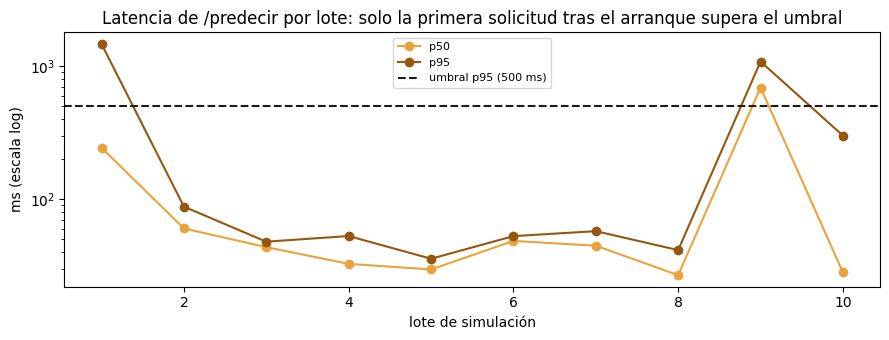

metrica,volumen_solicitudes,volumen_predicciones,latencia_p50_ms,latencia_p95_ms,pct_errores_4xx,pct_errores_5xx,pct_respaldo,pct_predicciones_faltantes
lote_simulacion,,,,,,,,
1,6.0,6.0,243.48,1464.66,0.0,0.0,0.0,0.0
2,6.0,6.0,60.42,88.06,0.0,0.0,0.0,0.0
3,6.0,6.0,43.74,48.07,0.0,0.0,0.0,0.0
4,6.0,6.0,32.79,53.00,0.0,0.0,0.0,0.0
5,5.0,5.0,29.75,35.81,0.0,0.0,0.0,0.0
6,3.0,3.0,48.70,52.92,0.0,0.0,0.0,0.0
7,5.0,5.0,44.85,57.66,0.0,0.0,0.0,0.0
8,6.0,6.0,26.96,41.58,0.0,0.0,0.0,0.0
9,2.0,2.0,688.84,1080.02,0.0,0.0,0.0,0.0


In [9]:
sistema = (mon[mon["tipo"] == "sistema"]
           .pivot_table(index="lote_simulacion", columns="metrica", values="valor"))
columnas = ["volumen_solicitudes", "volumen_predicciones", "latencia_p50_ms", "latencia_p95_ms",
            "pct_errores_4xx", "pct_errores_5xx", "pct_respaldo", "pct_predicciones_faltantes"]
sistema = sistema[[c for c in columnas if c in sistema.columns]]

fig, eje = plt.subplots(figsize=(9, 3.5))
eje.plot(sistema.index, sistema["latencia_p50_ms"], marker="o", color="#E8A33D", label="p50")
eje.plot(sistema.index, sistema["latencia_p95_ms"], marker="o", color="#94570F", label="p95")
eje.axhline(500, color="#1E1A16", linestyle="--", label="umbral p95 (500 ms)")
eje.set_yscale("log")
eje.set_xlabel("lote de simulación")
eje.set_ylabel("ms (escala log)")
eje.set_title("Latencia de /predecir por lote: solo la primera solicitud tras el arranque supera el umbral")
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()
sistema.round(2)

**Lectura.** En los 10 lotes llegaron 51 solicitudes a `/predecir` y se registraron 51 predicciones: ninguna se perdió. La tasa de errores fue 0 % de 4xx y 0 % de 5xx en todos los lotes: el contrato entre Kestra y la API se cumplió y la API no falló. Que la métrica de 4xx sí detecta rechazos se comprueba en CI con `test_rechazo_queda_registrado_con_codigo_y_lote` (un mes 13 queda registrado como 422 con su lote). La latencia p50 se mantiene entre 23 y 61 ms en los lotes 2 a 8 y 10; los lotes 1 y 9 son más altos porque su primera solicitud llegó con la API recién arrancada o inactiva.

**Conclusión del monitoreo**

- **Deriva de datos:** la deriva inducida del lote 10 se detecta con dos alertas que no aparecen en ningún lote normal (PSI de `generacion_levadura` y `carga_planta_14d` fuera de rango). Los cambios reales del proceso (`con_microscopio`, `carga_planta_14d`) se miden pero no alertan, porque el modelo no usa esas variables.
- **Efecto de la deriva en la decisión:** en el lote 10 la deriva no cambió la merma real (5 de 6 lotes con merma alta), pero bajó todas las probabilidades por debajo del umbral: el modelo con umbral fijo no recomendó ningún clarificante y su costo fue el mismo que no hacer nada (75,47 USD por lote). Es **deriva de datos con impacto en la decisión**, sin deriva conceptual.
- **Deriva conceptual y reentrenamiento:** el ROC-AUC de los lotes 7 (0,25) y 8 (0,00) quedó bajo el límite de la CV (0,389) dos lotes seguidos. Su merma real llegó dos semanas después, al monitorear los lotes 9 y 10, y por eso el reentrenamiento se disparó en el lote 10. Lo disparó la caída de desempeño de lotes normales, **no** la deriva inducida: la deriva de datos sola no reentrena, por diseño. Ese ROC-AUC se calcula con 5 o 6 lotes por semana (el lote 7 tiene un solo lote con merma baja), así que es una señal ruidosa; la regla de 2 lotes seguidos reduce, pero no elimina, ese ruido.
- **Decisión:** en las dos ejecuciones disparadas por la métrica, el challenger tuvo el mismo ROC-AUC que el champion (0,457) en la ventana de evaluación, pero costó más (50,66 vs. 33,04 USD por lote). La regla recomendó MANTENER y la persona responsable lo rechazó, con el motivo registrado en MLflow. El champion v1 siguió en producción, así que el reentrenamiento no cambió ninguna predicción de la simulación.
- **Sistema:** 51 solicitudes y 51 predicciones, 0 % de errores 4xx y 5xx, sin respaldo. Las únicas alertas de sistema son la latencia de la primera solicitud tras el arranque o la inactividad (lotes 1 y 9);; las de los lotes 8 y 10 de la primera simulación desaparecieron al sacar la consulta a MLflow de la solicitud.
- **Alertas en lotes normales:** el PSI de la probabilidad (lotes 1 y 2) es una falsa alarma por estacionalidad y tamaño de muestra; el exceso de presupuesto (5 semanas) es una alerta de negocio con su acción definida; los nulos del lote 8 son una falla real de registro.